# Détection de fraude à la carte bancaire : benchmark de modèles de Machine Learning

**Objectif :** comparer des modèles de Machine Learning (Random Forest, XGBoost, réseau de neurones) à un modèle classique, la **régression logistique**, pour détecter les transactions frauduleuses.

**Questions :**
1. Les modèles plus complexes détectent-ils mieux la fraude que la régression logistique ?
2. Comment expliquer leurs décisions aux équipes métier (SHAP) ?
3. Que représente ce gain en euros ?

**Données :** [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (ULB / Worldline) : 284 807 transactions de porteurs de cartes européens sur deux jours de septembre 2013. Les variables `V1` à `V28` sont issues d'une ACP (anonymisation), seules `Time` et `Amount` sont en clair.

## 1. Chargement et exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, precision_recall_curve,
                             confusion_matrix)
from xgboost import XGBClassifier
import shap

SEED = 42
df = pd.read_csv("creditcard.csv")
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())
print()
print(df["Class"].value_counts())
print(f"Taux de fraude : {df['Class'].mean():.3%}")

Valeurs manquantes : 0


Doublons : 1081

Class
0    284315
1       492
Name: count, dtype: int64
Taux de fraude : 0.173%


**Ce qu'on observe :** aucune valeur manquante. Il y a 1 081 lignes en double, que l'on garde : deux transactions identiques peuvent exister réellement et on ne peut pas le vérifier.

Surtout, les données sont **très déséquilibrées** : seulement 0,17 % des transactions sont des fraudes (492 sur 284 807). C'est le point le plus important du projet :
- un modèle qui dit toujours « pas de fraude » aurait 99,83 % d'*accuracy*, mais ne servirait à rien. On n'utilise donc **pas** l'accuracy ;
- on utilise l'**AUC-ROC**, la **PR-AUC** (aire sous la courbe précision-rappel) et le **F1-score**. La PR-AUC est la plus pertinente ici, car elle se concentre sur la classe rare (la fraude).

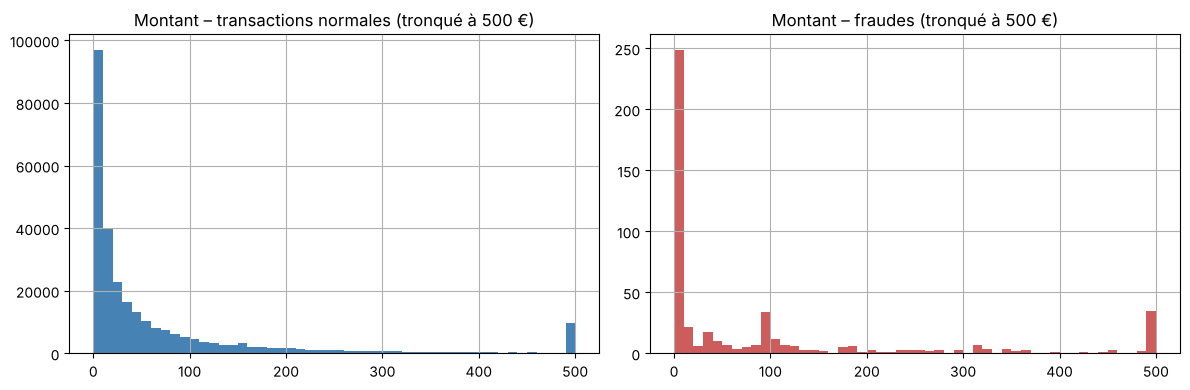

Montant médian – normales : 22.0
Montant médian – fraudes  : 9.25
Montant total des fraudes : 60128 €


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.loc[df.Class == 0, "Amount"].clip(upper=500).hist(bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Montant – transactions normales (tronqué à 500 €)")
df.loc[df.Class == 1, "Amount"].clip(upper=500).hist(bins=50, ax=axes[1], color="indianred")
axes[1].set_title("Montant – fraudes (tronqué à 500 €)")
plt.tight_layout(); plt.savefig("figures/montants.png", dpi=120); plt.show()

print("Montant médian – normales :", df.loc[df.Class == 0, "Amount"].median())
print("Montant médian – fraudes  :", df.loc[df.Class == 1, "Amount"].median())
print("Montant total des fraudes :", round(df.loc[df.Class == 1, "Amount"].sum()), "€")

Les fraudes portent souvent sur de **petits montants** (médiane autour de 9 €, contre 22 € pour les transactions normales) : les fraudeurs testent souvent une carte avec un petit achat. Le montant seul ne suffit donc pas à repérer une fraude.

## 2. Découpage des données

On sépare les données en trois parties, en gardant la même proportion de fraudes dans chacune (`stratify`) :
- **entraînement (60 %)** pour apprendre les modèles ;
- **validation (20 %)** pour choisir le **seuil de décision** de chaque modèle ;
- **test (20 %)** utilisé une seule fois à la fin, pour une évaluation honnête.

In [4]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

for nom, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{nom:11s} {len(yy):7d} lignes, {yy.sum():3d} fraudes")

train        170884 lignes, 295 fraudes
validation    56961 lignes,  98 fraudes
test          56962 lignes,  99 fraudes


## 3. Les modèles

| Modèle | Rôle | Gestion du déséquilibre |
|---|---|---|
| Régression logistique | **modèle de référence** (classique) | `class_weight="balanced"` |
| Random Forest | ensemble d'arbres | `class_weight="balanced_subsample"` |
| XGBoost | boosting d'arbres | `scale_pos_weight` = nb normales / nb fraudes |
| Réseau de neurones (MLP) | modèle non linéaire | données standardisées |

La régression logistique et le réseau de neurones ont besoin de variables à la même échelle, on les place donc dans un pipeline avec `StandardScaler`. Les arbres n'en ont pas besoin.

In [5]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

modeles = {
    "Régression logistique": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=ratio, eval_metric="aucpr",
        n_jobs=-1, random_state=SEED),
    "Réseau de neurones": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                      max_iter=200, random_state=SEED)),
}

proba_val, proba_test = {}, {}
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    proba_val[nom] = modele.predict_proba(X_val)[:, 1]
    proba_test[nom] = modele.predict_proba(X_test)[:, 1]
    print(f"{nom} : entraîné")

Régression logistique : entraîné


Random Forest : entraîné


XGBoost : entraîné


Réseau de neurones : entraîné


## 4. Choix du seuil de décision

Par défaut, un modèle classe une transaction comme fraude si sa probabilité dépasse 0,5. Avec des données aussi déséquilibrées, ce seuil n'est pas forcément le bon. Pour chaque modèle, on choisit sur la **validation** le seuil qui maximise le F1-score, puis on l'applique tel quel au test.

In [6]:
def meilleur_seuil(y_true, proba):
    precision, rappel, seuils = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * rappel / (precision + rappel + 1e-12)
    return seuils[np.argmax(f1[:-1])]

seuils = {nom: meilleur_seuil(y_val, p) for nom, p in proba_val.items()}
seuils

{'Régression logistique': np.float64(0.9999999980336132),
 'Random Forest': np.float64(0.40966535563827955),
 'XGBoost': np.float32(0.7919249),
 'Réseau de neurones': np.float64(0.30983689933802844)}

## 5. Résultats sur le jeu de test

In [7]:
lignes = []
for nom, p in proba_test.items():
    pred = (p >= seuils[nom]).astype(int)
    lignes.append({
        "Modèle": nom,
        "AUC-ROC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "Précision": precision_score(y_test, pred),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })
resultats = pd.DataFrame(lignes).set_index("Modèle").round(3)
resultats.to_csv("figures/resultats.csv")
resultats

,AUC-ROC,PR-AUC,Précision,Rappel,F1
Modèle,,,,,
Régression logistique,0.966,0.758,0.886,0.788,0.834
Random Forest,0.977,0.875,0.931,0.818,0.871
XGBoost,0.977,0.872,0.931,0.818,0.871
Réseau de neurones,0.958,0.854,0.844,0.818,0.831


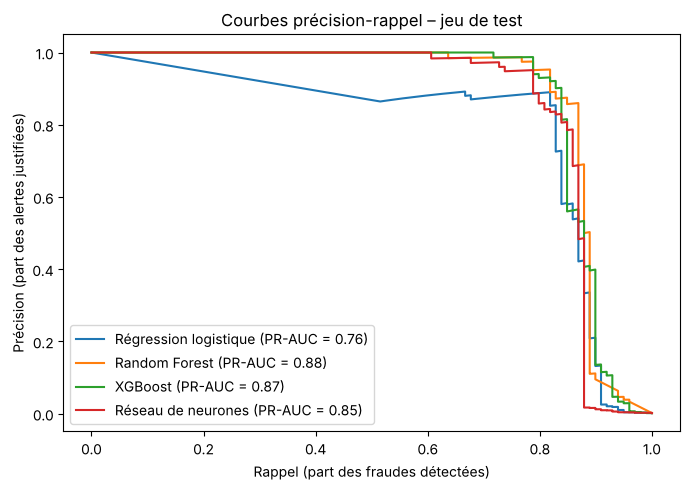

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for nom, p in proba_test.items():
    precision, rappel, _ = precision_recall_curve(y_test, p)
    ax.plot(rappel, precision, label=f"{nom} (PR-AUC = {average_precision_score(y_test, p):.2f})")
ax.set_xlabel("Rappel (part des fraudes détectées)")
ax.set_ylabel("Précision (part des alertes justifiées)")
ax.set_title("Courbes précision-rappel – jeu de test")
ax.legend(); plt.tight_layout(); plt.savefig("figures/courbes_pr.png", dpi=120); plt.show()

In [9]:
for nom in ["Régression logistique", "XGBoost"]:
    pred = (proba_test[nom] >= seuils[nom]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{nom} : {tp} fraudes détectées, {fn} manquées, {fp} fausses alertes")

Régression logistique : 78 fraudes détectées, 21 manquées, 10 fausses alertes
XGBoost : 81 fraudes détectées, 18 manquées, 6 fausses alertes


**Lecture des résultats :**
- L'**AUC-ROC** est élevée pour tous les modèles (0,96 à 0,98) : avec si peu de fraudes, elle départage mal les modèles.
- La **PR-AUC** montre un vrai écart : **0,87–0,88** pour XGBoost et Random Forest contre **0,76** pour la régression logistique. Les arbres classent bien mieux les transactions à risque.
- Au seuil choisi, XGBoost détecte **81 fraudes sur 99** avec **6 fausses alertes**, contre **78 fraudes** et **10 fausses alertes** pour la régression logistique (F1 : 0,87 contre 0,83).
- Le réseau de neurones a une bonne PR-AUC (0,85) mais génère plus de fausses alertes au seuil choisi.

**Attention :** le jeu de test ne contient que 99 fraudes. Un écart de 3 fraudes détectées reste petit ; la PR-AUC, qui résume tous les seuils possibles, est un indicateur plus stable.

## 6. Explicabilité (XAI) avec SHAP

Un modèle comme XGBoost est plus performant mais moins lisible qu'une régression logistique. **SHAP** mesure la contribution de chaque variable à chaque prédiction, ce qui permet d'expliquer :
- **globalement** quelles variables comptent le plus pour le modèle ;
- **localement** pourquoi une transaction donnée a été signalée.

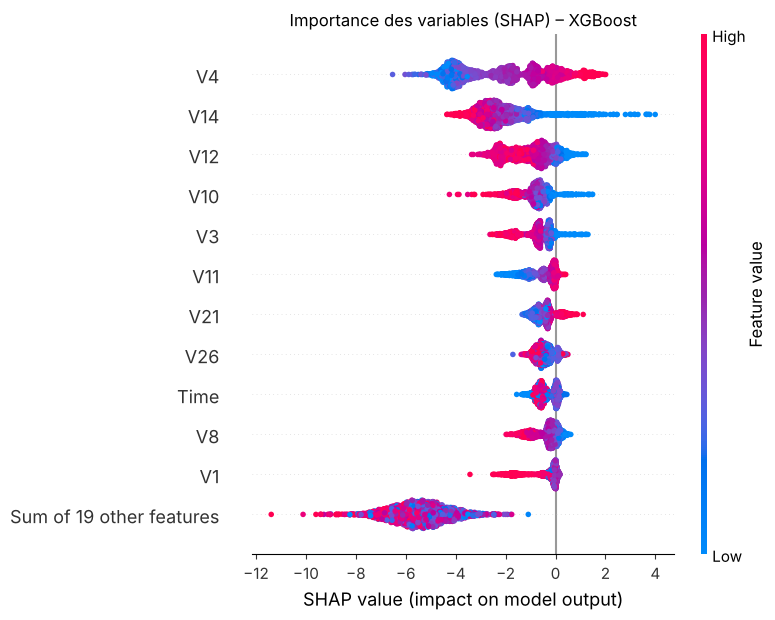

In [10]:
xgb = modeles["XGBoost"]
echantillon = X_test.sample(3000, random_state=SEED)
explainer = shap.TreeExplainer(xgb)
shap_values = explainer(echantillon)

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("Importance des variables (SHAP) – XGBoost")
plt.tight_layout(); plt.savefig("figures/shap_global.png", dpi=120, bbox_inches="tight"); plt.show()

Probabilité de fraude : 1.0


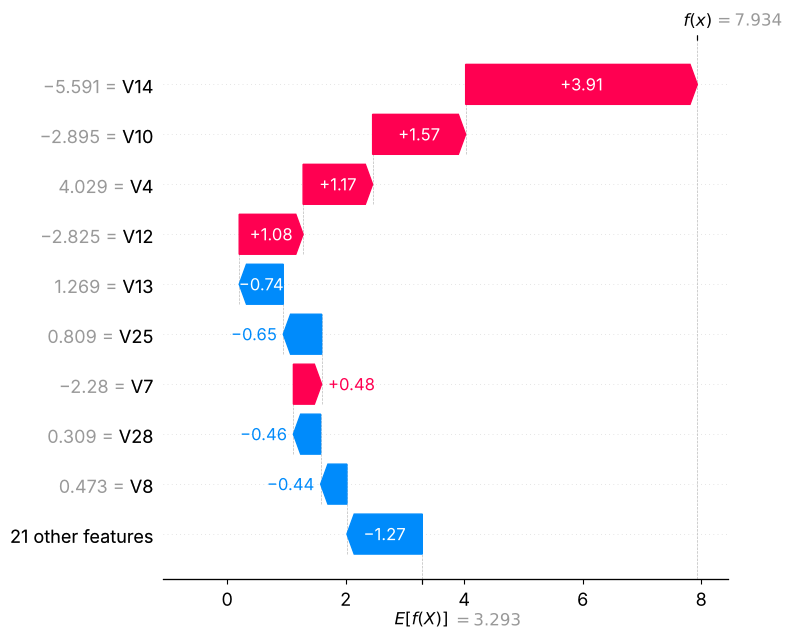

In [11]:
# Explication d'une fraude détectée par le modèle
fraudes_test = X_test[(y_test == 1) & (proba_test["XGBoost"] >= seuils["XGBoost"])]
exemple = explainer(fraudes_test.iloc[[0]])
print("Probabilité de fraude :", round(float(xgb.predict_proba(fraudes_test.iloc[[0]])[0, 1]), 3))
shap.plots.waterfall(exemple[0], max_display=10, show=False)
plt.tight_layout(); plt.savefig("figures/shap_exemple.png", dpi=120, bbox_inches="tight"); plt.show()

**Lecture :** quelques variables (surtout `V4`, `V14`, `V12` et `V10`) portent l'essentiel des décisions. Pour une transaction donnée, le graphique en cascade montre quelles variables ont fait monter ou baisser le risque.

**Limite :** ici, `V1` à `V28` sont anonymisées par ACP, on ne peut donc pas dire ce qu'elles représentent. Sur des données réelles de banque (type de commerçant, pays, heure, historique du client…), la même méthode donnerait des explications directement compréhensibles par les équipes métier.

## 7. Traduction en gains financiers

Pour passer des métriques statistiques à un impact business, on fixe des hypothèses simples (à adapter avec les équipes métier) :
- une **fraude manquée** coûte son **montant** (remboursé au client) ;
- une **fraude détectée** est bloquée : la perte est évitée ;
- chaque **alerte** (vraie ou fausse) coûte **5 €** de traitement (vérification, appel au client).

Le gain d'un modèle est la perte évitée moins le coût des alertes. On compare chaque modèle à la régression logistique.

In [12]:
COUT_ALERTE = 5
montants = X_test["Amount"].values
y_true = y_test.values

lignes = []
for nom, p in proba_test.items():
    alerte = p >= seuils[nom]
    perte_evitee = montants[alerte & (y_true == 1)].sum()
    perte_restante = montants[~alerte & (y_true == 1)].sum()
    cout_alertes = alerte.sum() * COUT_ALERTE
    lignes.append({"Modèle": nom, "Alertes": int(alerte.sum()),
                   "Perte évitée (€)": perte_evitee,
                   "Perte restante (€)": perte_restante,
                   "Coût des alertes (€)": cout_alertes,
                   "Gain net (€)": perte_evitee - cout_alertes})
roi = pd.DataFrame(lignes).set_index("Modèle").round(0)
roi["Écart vs régression logistique (€)"] = roi["Gain net (€)"] - roi.loc["Régression logistique", "Gain net (€)"]
roi.to_csv("figures/roi.csv")
roi

,Alertes,Perte évitée (€),Perte restante (€),Coût des alertes (€),Gain net (€),Écart vs régression logistique (€)
Modèle,,,,,,
Régression logistique,88,7239.0,2635.0,440,6799.0,0.0
Random Forest,87,7156.0,2718.0,435,6721.0,-78.0
XGBoost,87,7156.0,2718.0,435,6721.0,-78.0
Réseau de neurones,96,7150.0,2724.0,480,6670.0,-129.0


**Lecture :** résultat intéressant : malgré une meilleure PR-AUC, XGBoost ne fait **pas mieux** que la régression logistique en euros au seuil « F1 ». La régression logistique a détecté quelques fraudes de montant plus élevé. Le F1 traite toutes les fraudes de la même façon, alors que le coût réel dépend du **montant**. Le seuil qui maximise le F1 n'est donc pas forcément celui qui maximise le gain.

On choisit donc un nouveau seuil pour chaque modèle, cette fois en **maximisant le gain net sur la validation**, puis on l'applique au test.

In [13]:
def gain_net(y_true, proba, montants, seuil, cout=COUT_ALERTE):
    alerte = proba >= seuil
    return montants[alerte & (y_true == 1)].sum() - alerte.sum() * cout

montants_val = X_val["Amount"].values
grille = np.unique(np.quantile(np.concatenate(list(proba_val.values())), np.linspace(0.90, 1, 400)))

lignes = []
for nom in proba_val:
    gains_val = [gain_net(y_val.values, proba_val[nom], montants_val, s) for s in grille]
    s_cout = grille[int(np.argmax(gains_val))]
    alerte = proba_test[nom] >= s_cout
    lignes.append({"Modèle": nom, "Seuil (coût)": round(float(s_cout), 4),
                   "Fraudes détectées": int((alerte & (y_true == 1)).sum()),
                   "Alertes": int(alerte.sum()),
                   "Gain net test (€)": round(gain_net(y_true, proba_test[nom], montants, s_cout))})
roi_cout = pd.DataFrame(lignes).set_index("Modèle")
roi_cout["Écart vs régression logistique (€)"] = roi_cout["Gain net test (€)"] - roi_cout.loc["Régression logistique", "Gain net test (€)"]
roi_cout.to_csv("figures/roi_seuil_cout.csv")
roi_cout

,Seuil (coût),Fraudes détectées,Alertes,Gain net test (€),Écart vs régression logistique (€)
Modèle,,,,,
Régression logistique,1.0000,82,101,6859,0
Random Forest,0.2467,82,92,6697,-162
XGBoost,0.5046,82,89,6730,-129
Réseau de neurones,0.2832,81,97,6665,-194


**Lecture :** le tableau ci-dessus montre le gain obtenu quand le seuil est réglé sur le coût plutôt que sur le F1. Sur environ 57 000 transactions de test (20 % des deux jours de données, soit 99 fraudes), les écarts entre modèles se comptent en centaines d'euros. Ils restent sensibles au hasard, car quelques fraudes de montant élevé suffisent à changer le classement.

**Message pour le métier :** le choix du modèle et du seuil dépend du coût réel d'une alerte et d'une fraude manquée. Avant un déploiement, il faudrait valider ces coûts avec les équipes, puis mesurer le gain sur une période plus longue.

## 8. Conclusion et limites

**Conclusion**
- En capacité de détection (PR-AUC), **XGBoost et Random Forest** dépassent nettement la régression logistique (0,87–0,88 contre 0,76), avec moins de fausses alertes.
- En euros, l'avantage est beaucoup moins net : il dépend du **seuil** et des **hypothèses de coût**. Un meilleur score statistique ne garantit pas un meilleur gain financier.
- **SHAP** permet de garder un modèle plus performant tout en expliquant ses décisions, ce qui est indispensable dans un contexte bancaire.

**Limites et pistes**
- Le découpage est aléatoire. Sur des données réelles, il faudrait un découpage **temporel** (entraîner sur le passé, tester sur le futur), car la fraude évolue.
- Les variables sont anonymisées, ce qui limite l'interprétation métier.
- Pistes : réglage plus fin des hyperparamètres (validation croisée), coût d'alerte variable selon le montant, suivi de la performance dans le temps.